# Ivy experiments: what small from-scratch models learn, and what they don't

Ivy is a small language model meant to turn requests like *"move report.pdf to the archive on my laptop"* into tool calls.
Before committing months of GPU time to a 1.5B model, we ran a ladder of cheap experiments at **40M** and **300M** parameters.
This notebook reproduces every result from the dataset files.

1. **Learning rate**: where is the optimum for each size?
2. **Scaling**: is a bigger model or more data the better use of compute?
3. **Tool-use fine-tuning**: does the model *understand* requests, or match templates it has seen?

Code and full build log: https://github.com/Dhruv-Sharma29/Ivy-1.5b

In [1]:
import glob, json, math, os
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Dataset location: Kaggle input folder, or $IVY_DATA when run locally.
cands = [os.environ.get("IVY_DATA", ""), "/kaggle/input/ivy-experiments"] + [str(Path(p).parent) for p in glob.glob("/kaggle/input/*/runs.csv")]
DATA = next(Path(c) for c in cands if c and (Path(c) / "runs.csv").exists())
runs = pd.read_csv(DATA / "runs.csv")
print("data:", DATA)

# Chart style. Colours: a CVD-validated categorical order (blue, orange, aqua) and a one-hue ordinal ramp for ordered values.
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8984", "#e8e7e3"
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
RAMP4 = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 110,
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": MUTED, "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
})
TOK_PER_STEP = 65_536


def metrics(run):
    rows = [json.loads(l) for l in open(DATA / "runs" / run / "metrics.jsonl")]
    train = pd.DataFrame([r for r in rows if "loss" in r])
    val = pd.DataFrame([r for r in rows if "val_loss" in r]).drop_duplicates("step", keep="last")
    val["tokens"] = val["step"] * TOK_PER_STEP
    return train, val


def fmt_lr(v):
    m, e = f"{v:.1e}".split("e")
    return f"{m.rstrip('0').rstrip('.')}e{int(e)}"


def end_label(ax, x, y, text, dx=6, dy=0, ha="left"):
    ax.annotate(text, (x, y), xytext=(dx, dy), textcoords="offset points", va="center", ha=ha, fontsize=9, color=INK2)


def end_labels(ax, items, gap):
    # direct labels at line ends, nudged apart vertically (gap in data units) so they never overlap
    items = sorted(items, key=lambda t: t[1])
    ys = [t[1] for t in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (x, _, text), y in zip(items, ys):
        ax.annotate(text, (x, y), xytext=(8, y), textcoords=("offset points", "data"), va="center", fontsize=9, color=INK2)


runs

data: /workspace/ItsDS/Ivy-1.5B/kaggle/ivy-experiments


,run,kind,params_M,corpus,tokens_M,peak_lr,seed,base,sft_data,note
0,ivy-40m-pilot,pretrain,40.9,mix-v0,98.3,0.0006,1234,NaN,NaN,pipeline pilot; LR not swept
1,ivy-40m-lr-6e-4-100M,pretrain,40.9,mix-v1,98.3,0.0006,1234,NaN,NaN,40M LR sweep
2,ivy-40m-lr-1.2e-3-100M,pretrain,40.9,mix-v1,98.3,0.0012,1234,NaN,NaN,40M LR sweep
3,ivy-40m-lr-2.4e-3-100M,pretrain,40.9,mix-v1,98.3,0.0024,1234,NaN,NaN,40M LR sweep (best)
4,ivy-40m-lr-4.8e-3-100M,pretrain,40.9,mix-v1,98.3,0.0048,1234,NaN,NaN,40M LR sweep
5,ivy-40m-scale-300M-lr-2.4e-3,pretrain,40.9,mix-v1,300.0,0.0024,1234,NaN,NaN,40M token scaling
6,ivy-40m-scale-1000M-lr-2.4e-3,pretrain,40.9,mix-v1,1000.0,0.0024,1234,NaN,NaN,40M token scaling; base of sft-40m-*
7,ivy-300m-lr-3e-4,pretrain,307.3,mix-v0,98.3,0.0003,1234,NaN,NaN,300M LR sweep
8,ivy-300m-lr-6e-4,pretrain,307.3,mix-v0,98.3,0.0006,1234,NaN,NaN,300M LR sweep
9,ivy-300m-lr-1.2e-3,pretrain,307.3,mix-v0,98.3,0.0012,1234,NaN,NaN,300M LR sweep (best)


## 1. Learning-rate sweeps

Each size was trained for ~98M tokens at several peak learning rates, with everything else fixed (data order, init, schedule).
The 40M and 300M sweeps used different corpora (mix-v1 and mix-v0), so compare **where the optimum is**, not the loss levels
across panels.

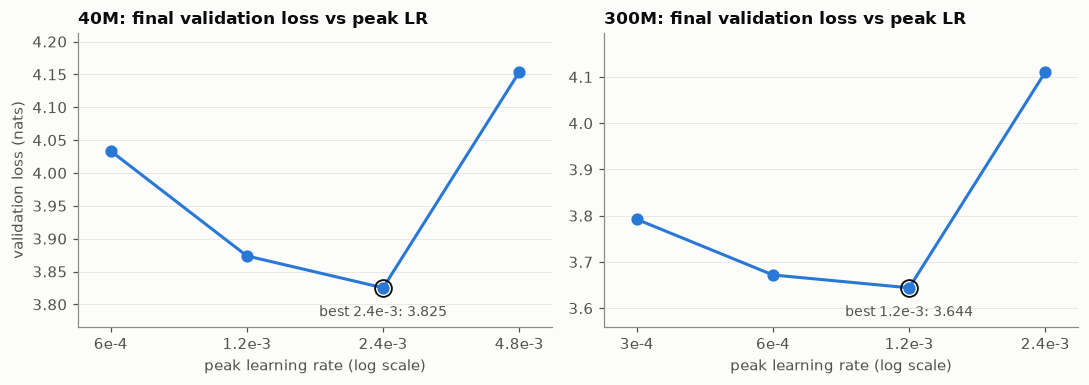

300M @1.2e-3 seed 1234: 3.6440  seed 4321: 3.6400  difference 0.0041


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (size, prefix) in zip(axes, [("40M", "ivy-40m-lr-"), ("300M", "ivy-300m-lr-")]):
    sub = runs[runs.run.str.startswith(prefix)].copy()
    sub["final_val"] = [metrics(r)[1].val_loss.iloc[-1] for r in sub.run]
    sub = sub.sort_values("peak_lr")
    ax.plot(sub.peak_lr, sub.final_val, "-o", color=C1)
    ax.set_xscale("log", base=2)
    ax.set_xticks(sub.peak_lr, [fmt_lr(v) for v in sub.peak_lr])
    ax.minorticks_off()
    ax.margins(x=0.08, y=0.18)
    best = sub.loc[sub.final_val.idxmin()]
    ax.plot(best.peak_lr, best.final_val, "o", ms=11, mfc="none", mec=INK, mew=1.2)
    end_label(ax, best.peak_lr, best.final_val, f"best {fmt_lr(best.peak_lr)}: {best.final_val:.3f}", dx=0, dy=-16, ha="center")
    ax.set_title(f"{size}: final validation loss vs peak LR")
    ax.set_xlabel("peak learning rate (log scale)")
axes[0].set_ylabel("validation loss (nats)")
plt.tight_layout(); plt.show()

# Seed noise for the best 300M LR: one replicate with a different seed.
a, b = (metrics(r)[1].val_loss.iloc[-1] for r in ["ivy-300m-lr-1.2e-3", "ivy-300m-rep-seed4321-lr-1.2e-3"])
print(f"300M @1.2e-3 seed 1234: {a:.4f}  seed 4321: {b:.4f}  difference {abs(a - b):.4f}")

Both optima are **inside** the tested range, and the smaller model prefers a higher rate (40M: 2.4e-3, 300M: 1.2e-3). The seed
replicate differs by only ~0.004, so the 0.028 gap between 1.2e-3 and 6e-4 at 300M is real. Only one batch size and one token
budget were tested.

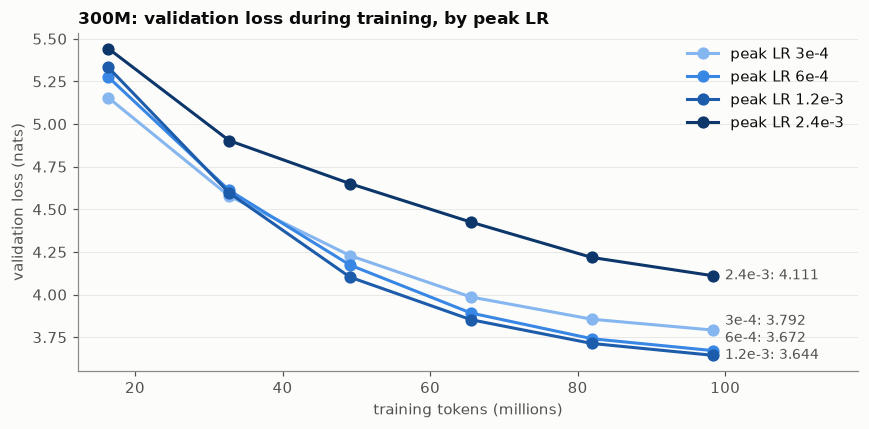

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
lrs = ["3e-4", "6e-4", "1.2e-3", "2.4e-3"]
ends = []
for lr, col in zip(lrs, RAMP4):
    _, v = metrics(f"ivy-300m-lr-{lr}")
    v = v[v.step >= 250]
    ax.plot(v.tokens / 1e6, v.val_loss, "-o", color=col, label=f"peak LR {lr}")
    ends.append((v.tokens.iloc[-1] / 1e6, v.val_loss.iloc[-1], f"{lr}: {v.val_loss.iloc[-1]:.3f}"))
end_labels(ax, ends, gap=0.1)
ax.set_title("300M: validation loss during training, by peak LR")
ax.set_xlabel("training tokens (millions)"); ax.set_ylabel("validation loss (nats)")
ax.set_xlim(right=118)
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 2. Scaling: bigger model or more data?

All numbers in this section use **one common validation set** (`reports/scaling-common-eval.json`), so models are comparable.
(The in-training validation numbers are not: their window sample depends on the micro-batch size, which differed between runs.)
Compute is approximated as 6 · parameters · tokens.

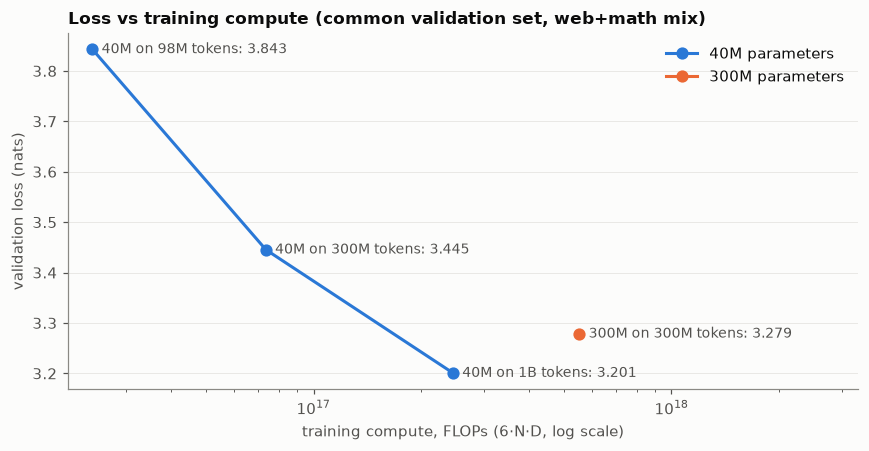

,model,tokens_M,web,math,mix,flops
0,40M,98.3,4.019,3.015,3.843,2.412282e+16
1,40M,300.0,3.613,2.633,3.445,7.362000e+16
2,40M,1000.0,3.367,2.393,3.201,2.454000e+17
5,300M,300.0,3.443,2.482,3.279,5.531400e+17


In [4]:
ce = pd.DataFrame(json.load(open(DATA / "reports" / "scaling-common-eval.json")))
ce = ce[ce.train_corpus == "mix-v1"].copy()        # the 300M@98M runs used another corpus: left out of this comparison
ce["flops"] = 6 * ce.params_M * 1e6 * ce.tokens_M * 1e6
fig, ax = plt.subplots(figsize=(8, 4.2))
for model, col in [("40M", C1), ("300M", C2)]:
    s = ce[ce.model == model].sort_values("flops")
    ax.plot(s.flops, s.mix, "-o", color=col, label=f"{model} parameters")
    for _, r in s.iterrows():
        tok = f"{r.tokens_M / 1000:g}B" if r.tokens_M >= 1000 else f"{r.tokens_M:.0f}M"
        end_label(ax, r.flops, r.mix, f"{model} on {tok} tokens: {r.mix:.3f}")
ax.set_xscale("log")
ax.set_title("Loss vs training compute (common validation set, web+math mix)")
ax.set_xlabel("training compute, FLOPs (6·N·D, log scale)"); ax.set_ylabel("validation loss (nats)")
ax.set_xlim(right=ce.flops.max() * 6)
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
ce[["model", "tokens_M", "web", "math", "mix", "flops"]].round(3)

The **40M model on 1B tokens (3.201) beats the 300M model on 300M tokens (3.279) with about 2× less compute.** At ~1 token per
parameter the 300M model is badly under-trained. With only two sizes and three token budgets this is a direction, not a scaling
law (see `reports/scaling-fit-rough.json` for a deliberately rough fit).

Training trajectories of the three mix-v1 runs (in-training validation, so the 300M curve is on a different window sample and
can be off by ~0.03):

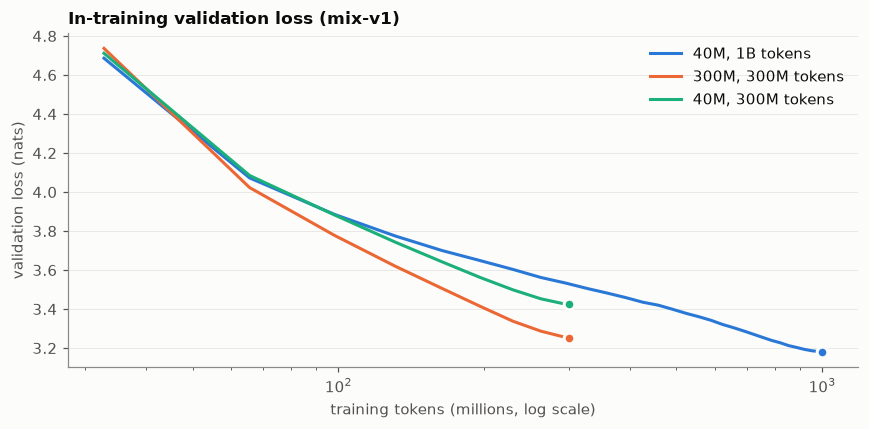

,run,tokens_M,final in-training val loss
0,"40M, 1B tokens",1000,3.180
1,"300M, 300M tokens",300,3.252
2,"40M, 300M tokens",300,3.424


In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
final = []
for run, label, col in [("ivy-40m-scale-1000M-lr-2.4e-3", "40M, 1B tokens", C1), ("ivy-300m-scale-300M-lr-1.2e-3", "300M, 300M tokens", C2),
                        ("ivy-40m-scale-300M-lr-2.4e-3", "40M, 300M tokens", C3)]:
    _, v = metrics(run)
    v = v[v.step >= 500]
    ax.plot(v.tokens / 1e6, v.val_loss, "-", color=col, label=label)
    ax.plot(v.tokens.iloc[-1] / 1e6, v.val_loss.iloc[-1], "o", color=col, mec=SURFACE, mew=2)
    final.append({"run": label, "tokens_M": round(v.tokens.iloc[-1] / 1e6), "final in-training val loss": round(v.val_loss.iloc[-1], 3)})
ax.set_xscale("log")
ax.set_title("In-training validation loss (mix-v1)")
ax.set_xlabel("training tokens (millions, log scale)"); ax.set_ylabel("validation loss (nats)")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
pd.DataFrame(final)

## 3. Tool-use fine-tuning: understanding or template matching?

Each pretrained base was fine-tuned (SFT) on ~20k **template-generated** examples. Every phrasing list and slot-value pool
(apps, paths, messages…) was split by a stable hash: ~30% held out. Two training sets:

- **v0**: all templates, including the ones later held out;
- **v1-train**: the held-out templates and slot values are never seen.

Two test sets of 600: **in-dist** (new combinations of training templates) and **held-out** (only held-out templates and values).
Same base and recipe; only the SFT data differs. Scores count a tool call as correct only if tool, device and arguments all match.

In [6]:
SETS = ["v1", "v2", "sft_indist", "sft_heldout"]
sft = runs[runs.kind == "sft"].run.tolist()
rows = []
for r in sft:
    meta = runs.set_index("run").loc[r]
    for s in SETS:
        sc = json.load(open(DATA / "runs" / r / f"score_{s}.json"))
        rows.append({"run": r, "size": "40M" if meta.params_M < 100 else "300M", "sft_data": meta.sft_data, "set": s,
                     "acc": sc["accuracy"], "lo": sc["accuracy_95ci"][0], "hi": sc["accuracy_95ci"][1],
                     "unsafe": sc["unsafe_executable_mismatch"], "n": sc["n"]})
res = pd.DataFrame(rows)
(res.pivot_table(index=["size", "sft_data"], columns="set", values="acc").reindex(columns=SETS) * 100).round(1)

set              v1    v2  sft_indist  sft_heldout
size sft_data                                     
300M v0        51.1  69.6        92.8         92.8
     v1-train  43.1  55.4        91.8         45.3
40M  v0        52.9  67.3        92.5         90.5
     v1-train  45.3  58.1        91.8         55.7

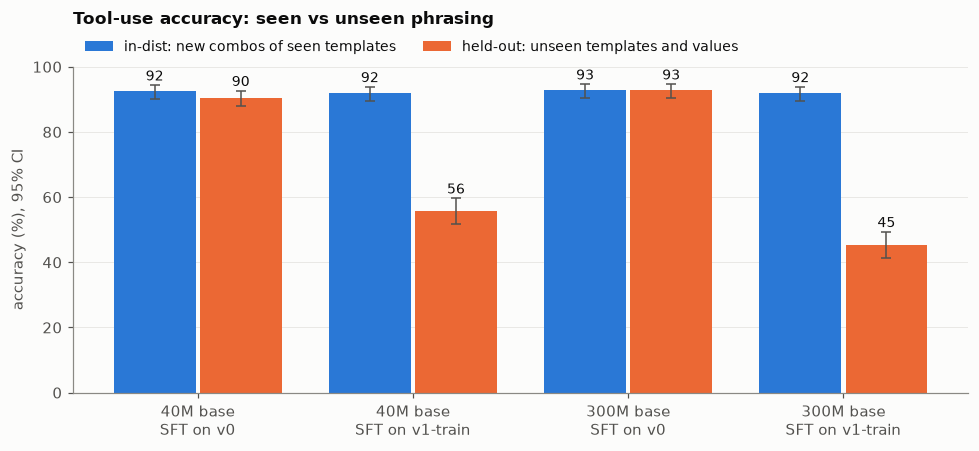

In [7]:
order = [("40M", "v0"), ("40M", "v1-train"), ("300M", "v0"), ("300M", "v1-train")]
fig, ax = plt.subplots(figsize=(9, 4.2))
w = 0.38
for j, (s, col, lab) in enumerate([("sft_indist", C1, "in-dist: new combos of seen templates"), ("sft_heldout", C2, "held-out: unseen templates and values")]):
    for i, (size, data) in enumerate(order):
        r = res[(res["size"] == size) & (res.sft_data == data) & (res.set == s)].iloc[0]
        x = i + (j - 0.5) * (w + 0.02)
        ax.bar(x, r.acc * 100, w, color=col, label=lab if i == 0 else None, zorder=2)
        ax.errorbar(x, r.acc * 100, yerr=[[100 * (r.acc - r.lo)], [100 * (r.hi - r.acc)]], fmt="none", ecolor=INK2, elinewidth=1, capsize=3, zorder=3)
        ax.text(x, r.hi * 100 + 1.5, f"{r.acc * 100:.0f}", ha="center", fontsize=9, color=INK)
ax.set_xticks(range(4), [f"{s} base\nSFT on {d}" for s, d in order])
ax.set_ylim(0, 100); ax.set_ylabel("accuracy (%), 95% CI")
ax.set_title("Tool-use accuracy: seen vs unseen phrasing", pad=28)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
plt.tight_layout(); plt.show()

When the held-out templates were in training (v0), held-out accuracy is close to in-dist. When they were not (v1-train),
**accuracy on unseen phrasing collapses**, by ~35 points at 40M, while in-dist stays at ~92%. The models match templates rather
than generalise. And the 300M model (with its under-trained base) transfers **worse** than the 40M one. Is that difference real?
Both models answered the same 600 items, so a paired test applies:

In [8]:
def parse(raw):
    try:
        o = json.loads(raw)
    except (json.JSONDecodeError, TypeError):
        return None
    return o if isinstance(o, dict) else None


def matches(o, e):
    if o.get("action") != e["action"]:
        return False
    return e["action"] != "tool_call" or (o.get("tool"), o.get("device"), o.get("args")) == (e["tool"], e["device"], e["args"])


scen = {s: [json.loads(l) for l in open(DATA / "evals" / f"{s}.jsonl")] for s in ["sft_indist", "sft_heldout"]}


def per_item(run, s):
    out = {r["id"]: r["output"] for r in map(json.loads, open(DATA / "runs" / run / f"outputs_{s}.jsonl"))}
    return {x["id"]: (parse(out.get(x["id"], "")), x) for x in scen[s]}


def correct(o, x):
    return o is not None and (matches(o, x["expected"]) or any(matches(o, a) for a in x.get("accept_alternatives", [])))


for s in ["sft_indist", "sft_heldout"]:
    a, b = per_item("sft-40m-1b-v1train", s), per_item("sft-300m-300m-v1train", s)
    only_b = sum(correct(*b[k]) and not correct(*a[k]) for k in a)
    only_a = sum(correct(*a[k]) and not correct(*b[k]) for k in a)
    n, k = only_a + only_b, min(only_a, only_b)
    p = min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)   # exact two-sided McNemar
    print(f"{s:12s} only 40M right: {only_a:3d}   only 300M right: {only_b:3d}   McNemar p = {p:.2g}")

sft_indist   only 40M right:   9   only 300M right:   9   McNemar p = 1
sft_heldout  only 40M right: 104   only 300M right:  42   McNemar p = 3e-07


On held-out items the 40M model wins clearly (p < 0.001); on in-dist the two are tied. Caveat: this compares two bases of similar
*compute*, not size at equal quality (the 300M base has worse language-model loss), and the SFT learning rates differ
(2e-4 vs 1e-4, neither tuned).

### What goes wrong on unseen phrasing

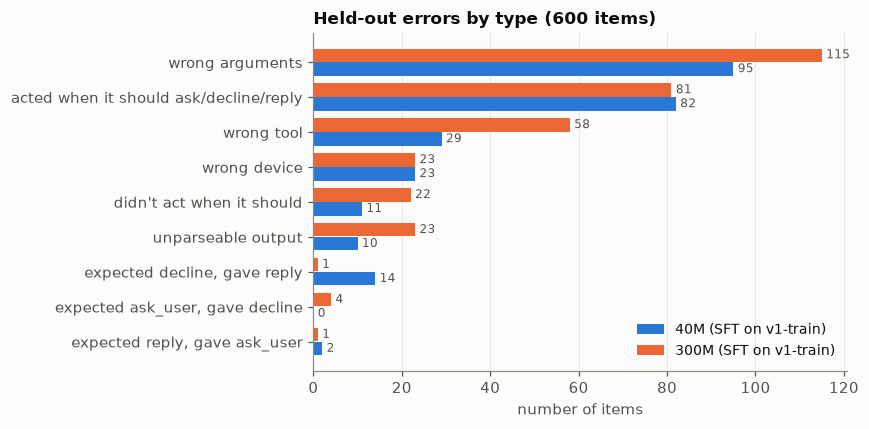

,40M,300M
wrong arguments,95,115
acted when it should ask/decline/reply,82,81
wrong tool,29,58
wrong device,23,23
didn't act when it should,11,22
unparseable output,10,23
"expected decline, gave reply",14,1
"expected ask_user, gave decline",0,4
"expected reply, gave ask_user",2,1


In [9]:
def error_type(o, x):
    e = x["expected"]
    if o is None:
        return "unparseable output"
    if o.get("action") != e["action"]:
        return {"tool_call": "acted when it should ask/decline/reply"}.get(o.get("action"), f"expected {e['action']}, gave {o.get('action')}") \
            if e["action"] != "tool_call" else "didn't act when it should"
    if o.get("tool") != e["tool"]:
        return "wrong tool"
    if o.get("device") != e["device"]:
        return "wrong device"
    return "wrong arguments"


errs = {}
for run, label in [("sft-40m-1b-v1train", "40M"), ("sft-300m-300m-v1train", "300M")]:
    items = per_item(run, "sft_heldout")
    errs[label] = Counter(error_type(o, x) for o, x in items.values() if not correct(o, x))
err = pd.DataFrame(errs).fillna(0).astype(int)
err = err.loc[err.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(8, 4))
h = 0.38
for j, (label, col) in enumerate([("40M", C1), ("300M", C2)]):
    y = [i + (j - 0.5) * (h + 0.02) for i in range(len(err))]
    ax.barh(y, err[label], h, color=col, label=f"{label} (SFT on v1-train)", zorder=2)
    for yy, v in zip(y, err[label]):
        ax.text(v + 1, yy, str(v), va="center", fontsize=8, color=INK2)
ax.set_yticks(range(len(err)), err.index)
ax.grid(axis="x", color=GRID, linewidth=0.6); ax.grid(axis="y", visible=False)
ax.set_title("Held-out errors by type (600 items)")
ax.set_xlabel("number of items")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()
err.iloc[::-1]

The largest group is **wrong arguments**: app names or paths never seen in training are not copied but replaced by memorised
ones (e.g. *"I need WhatsApp open"* → `name: "App"`). Policies (ask when information is missing, decline unsupported requests,
cancel) don't transfer to new wordings either.

One weakness does **not** depend on phrasing: reading the device list. When exactly one device has the requested tool, the model
should use it without asking:

In [10]:
cat = []
for r in sft:
    meta = runs.set_index("run").loc[r]
    for s in ["sft_indist", "sft_heldout"]:
        bc = json.load(open(DATA / "runs" / r / f"score_{s}.json"))["by_category"]
        for c in ["unique_capability", "ask_device", "single", "named_device"]:
            if c in bc:
                cat.append({"model": f"{'40M' if meta.params_M < 100 else '300M'} / SFT {meta.sft_data}", "set": s, "category": c,
                            "acc %": round(100 * bc[c]["correct"] / bc[c]["n"], 1), "n": bc[c]["n"]})
pd.DataFrame(cat).pivot_table(index="model", columns=["category", "set"], values="acc %")

category             ask_device            named_device             \
set                 sft_heldout sft_indist  sft_heldout sft_indist   
model                                                                
300M / SFT v0              72.4       42.9        100.0      100.0   
300M / SFT v1-train        27.6       10.7         51.1      100.0   
40M / SFT v0               34.5       35.7         97.9      100.0   
40M / SFT v1-train         17.2       17.9         66.0      100.0   

category                 single            unique_capability             
set                 sft_heldout sft_indist       sft_heldout sft_indist  
model                                                                    
300M / SFT v0             100.0      100.0              35.8       47.1  
300M / SFT v1-train        42.8      100.0              22.6       52.9  
40M / SFT v0              100.0      100.0              32.1       49.0  
40M / SFT v1-train         58.5      100.0              35.8       49.0

`single` and `named_device` (the device is obvious or named) are perfect on seen phrasing. `unique_capability` (exactly one
device lists the tool) stays at roughly 23–53% for **every** model and test set, i.e. near chance between 2–3 devices: looking a
tool up in the device list is a skill none of these models learned. `ask_device` (several devices fit, so ask) is also weak but
noisy (n ≈ 28 per cell, 11–72%).

## Takeaways

- **LR**: optimum inside the tested range for both sizes; smaller models want higher LR.
- **Scaling**: at this budget, more tokens beat more parameters (40M@1B < 300M@300M in loss, at half the compute).
- **Tool use**: template-trained small models score ~92% on familiar phrasing and ~45–56% on unseen phrasing. The bottleneck is
  **data diversity** (and a device-lookup skill), not parameter count, at least up to an under-trained 300M.

**Limits**: one seed per configuration (except one replicate); one author wrote both templates and evals, so even "held-out" is
closer to the training data than real users would be; SFT hyperparameters were not tuned.